# NIfTI orientation: the right-hand rule phantom

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cest-sources/imaging_science_tools/blob/main/4_nii_orientation/right_hand_rule_phantom.ipynb)

[Open in Colab](https://colab.research.google.com/github/cest-sources/imaging_science_tools/blob/main/4_nii_orientation/right_hand_rule_phantom.ipynb). The first cell installs the packages with `!pip`. Run this notebook from the `4_nii_orientation` folder.

This notebook builds a NIfTI of a hand in the pose of the usual right-hand-rule drawing, then opens it in [NiiVue](https://github.com/niivue/niivue).

Here you will learn:

- how the NIfTI world axes R, A, S (+X, +Y, +Z) form a right-handed triad, shown by thumb, index, and middle finger
- why a hand is a good test object: a mirrored right hand looks like a left hand, while a mirrored brain looks almost the same
- what the **neurological** and the **radiological** view are, which side of the body each one looks from, and why both are in use
- how to read the R/L letters instead of trusting the left and right of the screen

The source image is the healthy-adult hand template of Hegdé et al., the NIfTI behind [NIH 3D entry 17237](https://3d.nih.gov/entries/17237). NIH 3D hosts the surface that was segmented from that image. The image itself is [`Hegde_etal_Healthy_adult_hand_template.nii`](https://github.com/HegdeUSA/Hand_template) (MIT). It is an open hand: four fingers point the same way, and the thumb is only partly out to the side.

The warp hinges the digits:

- The palm, the index finger, and the thumb lie in the world XY plane.
- The index finger points along **+Y**.
- The thumb points along **+X**.
- The middle finger points along **+Z**, out of the palm toward the viewer (the dot in the drawing). +Z is the front of the hand.
- Ring and pinky fold all the way back and lie flat on the palm. The little finger angles in toward the middle of the palm, and where the two meet they may overlap.

World +X, +Y, +Z are a right-handed triad: thumb × index = middle finger. In NIfTI that is the same triad as R × A = S, so NiiVue's labels read R for the thumb, A for the index, and S for the middle finger.

Scroll a slice. Drag the 3D panel. On GitHub the NiiVue panel is empty until you run the cells.


In [1]:
!pip install -q nibabel scipy matplotlib ipywidgets ipyniivue


In [2]:
%matplotlib inline

from pathlib import Path
import urllib.request
import zipfile

import ipywidgets as widgets
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
from nibabel.affines import apply_affine
from ipyniivue import MultiplanarType, NiiVue, ShowRender, SliceType, Volume

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

HERE = Path.cwd()
if not (HERE / "make_right_hand_rule_phantom.py").exists():
    HERE = Path("4_nii_orientation")
if not (HERE / "make_right_hand_rule_phantom.py").exists():
    url = (
        "https://raw.githubusercontent.com/cest-sources/imaging_science_tools/"
        "main/4_nii_orientation/make_right_hand_rule_phantom.py"
    )
    urllib.request.urlretrieve(url, "make_right_hand_rule_phantom.py")
    HERE = Path.cwd()

import sys
sys.path.insert(0, str(HERE))
from make_right_hand_rule_phantom import build_phantom, save_phantom

DATA = HERE / "data"
DATA.mkdir(exist_ok=True)
PHANTOM = HERE / "right_hand_rule_phantom.nii.gz"
TEMPLATE_URL = (
    "https://raw.githubusercontent.com/HegdeUSA/Hand_template/main/Hand_template_image.zip"
)

def fetch_template():
    nii = DATA / "Hegde_etal_Healthy_adult_hand_template.nii"
    if nii.exists():
        return nii
    zpath = DATA / "Hand_template_image.zip"
    urllib.request.urlretrieve(TEMPLATE_URL, zpath)
    with zipfile.ZipFile(zpath) as zf:
        zf.extractall(DATA)
    return nii

source = fetch_template()
volume, affine, report = build_phantom(source)
save_phantom(PHANTOM, volume, affine)

print(f"saved {PHANTOM.name}  shape {volume.shape}  voxel 1 mm")
print("direction of each digit, tip minus base, in mm:")
for name in ("thumb", "index", "middle", "ring", "pinky"):
    d = report[name]["direction_mm"]
    print(f"  {name:7s}  {d[0]:7.1f}  {d[1]:7.1f}  {d[2]:7.1f}")
thumb = report["thumb"]["direction_mm"]
index = report["index"]["direction_mm"]
middle = report["middle"]["direction_mm"]
cross = np.cross(thumb / np.linalg.norm(thumb), index / np.linalg.norm(index))
print(f"thumb x index, dotted with the middle finger: {np.dot(cross, middle / np.linalg.norm(middle)):.2f}")


saved right_hand_rule_phantom.nii.gz  shape (169, 230, 100)  voxel 1 mm
direction of each digit, tip minus base, in mm:
  thumb       33.9      1.6      0.3
  index        0.0     61.3      0.4
  middle      -0.5     17.8     61.2
  ring        -7.7    -40.0     23.7
  pinky       15.6    -21.5     18.4
thumb x index, dotted with the middle finger: 0.96


## Three views

The file is a 1 mm grid. Voxel `i` steps in +X, `j` in +Y, `k` in +Z. The determinant of the affine is +1.

- **From +Z** you look at the palm, the way the drawing is shown. Index is up, thumb is to the right, and the middle finger points at you.
- **From +X** the index runs horizontally and the middle finger runs vertically.
- **From −Y**, the wrist side, the thumb runs horizontally to the right and the middle finger runs vertically.

Ring and pinky lie flat on the palm, folded back toward the wrist. The little finger points inward, toward the middle of the palm.

Each panel is a real camera position. Looking from +Z at the palm, +X is on your right. Looking from the other side, +X would be on your left. Keep that in mind for the next section.


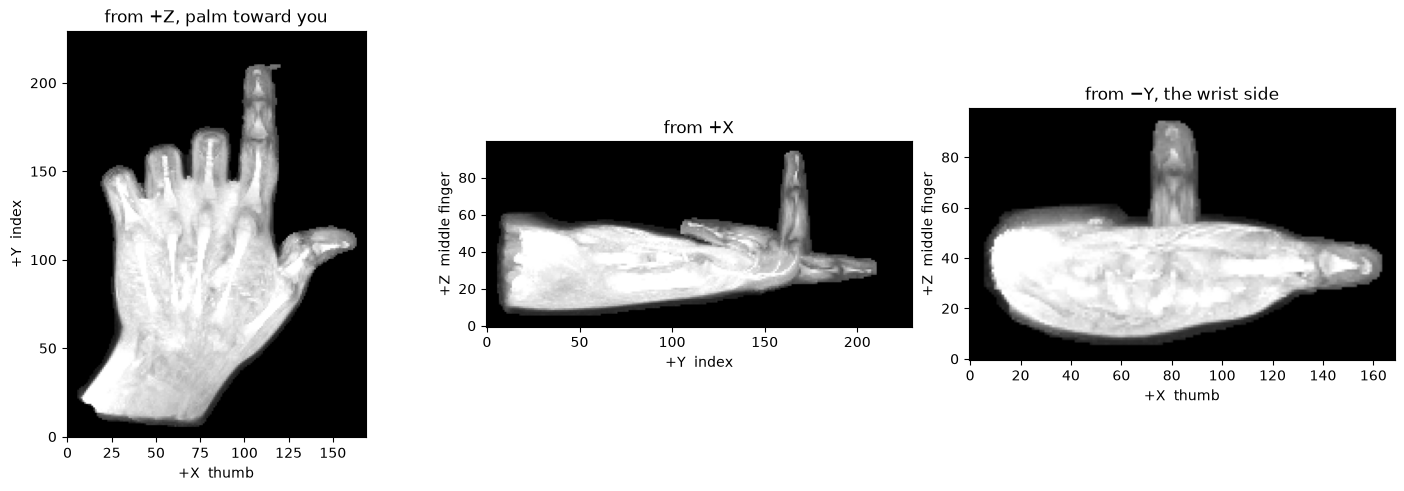

In [3]:
img = nib.load(PHANTOM)
data = np.asanyarray(img.dataobj)
vmax = float(np.percentile(data[data > 0], 99))

def show(ax, image, title, xlabel, ylabel):
    ax.imshow(image, origin="lower", cmap="gray", vmin=0, vmax=vmax)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), layout="constrained")
show(axes[0], data.max(axis=2).T, "from +Z, palm toward you", "+X  thumb", "+Y  index")
show(axes[1], data.max(axis=0).T, "from +X", "+Y  index", "+Z  middle finger")
show(axes[2], data.max(axis=1).T, "from −Y, the wrist side", "+X  thumb", "+Z  middle finger")
plt.show()


## Neurological and radiological view

The same file can be drawn on screen in two ways. **The data array and the affine do not change. Only the drawing is mirrored left to right.** That is why every serious viewer prints the R and L letters at the edges, and why you should read those letters, not the left and right of your screen.

| view | patient's right appears | axial slice is seen from | coronal slice is seen from | used in |
| --- | --- | --- | --- | --- |
| **neurological** | on the right of the screen ("left is left") | above, the head end | behind | neuroscience, brain atlases and research tools, for example SPM |
| **radiological** | on the left of the screen | below, the feet | the front | clinical radiology: CT, MRI, and X-ray reading and hospital image archives (PACS) |

Neither view is a trick. Each one is a real camera position:

- **Radiological** is the doctor's view. A radiograph is read as if you face the patient, like shaking hands: the patient's right is on your left. An axial CT or MRI slice of a patient lying on the back is seen from the foot of the bed. Clinics adopted this so that every reader and every scanner shows the same picture, and that habit is the standard on clinical workstations.
- **Neurological** is the anatomist's and neuroscientist's view. You look at the brain from above or from behind, the way you see your own head in a drawing or a dissection: left is left. Screen x then grows to the right with the R coordinate, so figures, atlases, and coordinates read the same way.

Why it matters: brains are almost symmetric. A mirrored brain slice still looks like a brain, so a left–right swap is invisible unless you check the letters. In a clinic the result can be a wrong-side diagnosis or wrong-side surgery. Always state a finding as the patient's left or right, and always check which view a figure uses.

The hand phantom makes the mirror visible, because a hand is chiral:

- **Neurological axial** (from +Z): you see the palm, thumb on the right, index up, middle finger pointing at you, the ⊙ "toward" symbol of the drawing.
- **Radiological axial** (from −Z): you see the back of the same hand. The thumb is now on the left and the middle finger points away from you, the ⊗ "away" symbol.

Both pictures show a right hand. A right hand seen from its back has the thumb on the left. If you forget which side the camera is on, the radiological picture reads as a left hand palm, and every left and right in it is swapped. The letters R and L are the only reliable clue.

A different idea with a similar name: some files store the voxels from right to left (the first voxel index grows toward the patient's left), sometimes called "radiological storage order". That is the order of the array in the file. The affine maps it to world R, A, S, so a correct viewer draws it correctly. The view button changes the screen, not the file.

The figure below draws the same projections both ways. Axial is the palm plane (constant Z), coronal is the plane across the hand (constant Y). The sagittal plane (constant X) has no left or right in it, so it is the same in both views.

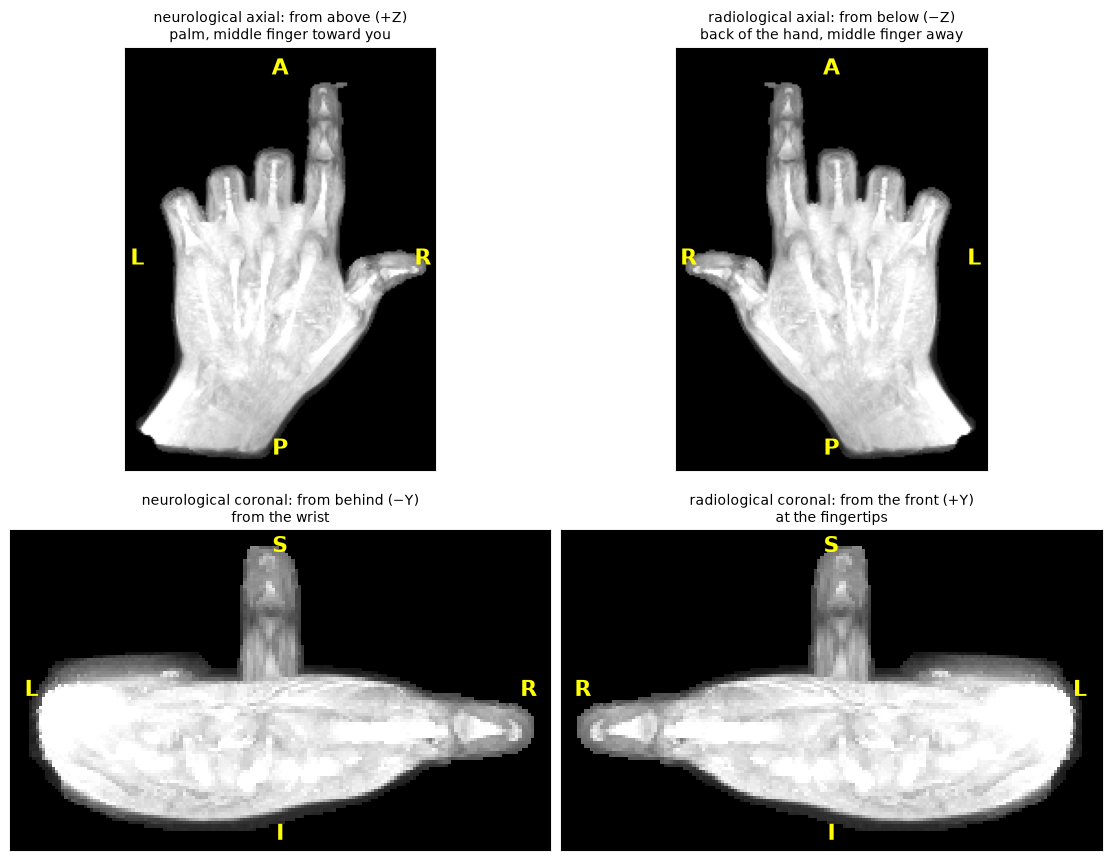

In [4]:
axial = data.max(axis=2).T     # rows +Y (A), columns +X (R)
coronal = data.max(axis=1).T   # rows +Z (S), columns +X (R)

def show_view(ax, image, title, left, right, top, bottom, mirror):
    if mirror:
        image = image[:, ::-1]
        left, right = right, left
    ax.imshow(image, origin="lower", cmap="gray", vmin=0, vmax=vmax)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    style = dict(color="yellow", fontsize=16, fontweight="bold", ha="center", va="center")
    ax.text(0.04, 0.5, left, transform=ax.transAxes, **style)
    ax.text(0.96, 0.5, right, transform=ax.transAxes, **style)
    ax.text(0.5, 0.95, top, transform=ax.transAxes, **style)
    ax.text(0.5, 0.05, bottom, transform=ax.transAxes, **style)

fig, axes = plt.subplots(2, 2, figsize=(11, 9), layout="constrained")
show_view(axes[0, 0], axial, "neurological axial: from above (+Z)\npalm, middle finger toward you",
          "L", "R", "A", "P", mirror=False)
show_view(axes[0, 1], axial, "radiological axial: from below (−Z)\nback of the hand, middle finger away",
          "L", "R", "A", "P", mirror=True)
show_view(axes[1, 0], coronal, "neurological coronal: from behind (−Y)\nfrom the wrist",
          "L", "R", "S", "I", mirror=False)
show_view(axes[1, 1], coronal, "radiological coronal: from the front (+Y)\nat the fingertips",
          "L", "R", "S", "I", mirror=True)
plt.show()

## NiiVue

The viewer draws the same file. Edge labels are the world axes of this phantom: **R** is the thumb (+X), **A** is the index (+Y), **S** is the middle finger (+Z). **L**, **P**, and **I** are the opposite ends of those axes.

The crosshair starts at the middle-finger knuckle. Scroll to move a slice. Drag inside the 3D panel to turn the hand. One button switches radiologic and neurologic view. The other switches the crosshair between world millimetres and voxel indices.

Try the view button:

1. Start in **neurological** view. In the axial panel the thumb is on the right, next to the R letter.
2. Press the button. In the axial and coronal panels the hand flips: the thumb moves to the left, and the R letter moves with it.
3. The sagittal panel does not change, and the 3D render does not change. The file is the same; only the 2D drawing is mirrored.
4. In both views the thumb sits next to R. That is the check to do with any image: find the letter, then name the side.


In [5]:
def show_niivue(path, vmax, crosshair_mm, height=560):
    nv = NiiVue(
        height=height,
        slice_type=SliceType.MULTIPLANAR,
        multiplanar_show_render=ShowRender.ALWAYS,
        multiplanar_layout=MultiplanarType.GRID,
        is_slice_mm=True,
        is_colorbar=True,
        is_radiological_convention=False,
        is_orientation_text_visible=True,
        show_all_orientation_markers=True,
        is_corner_orientation_text=False,
        font_color=(1.0, 1.0, 1.0, 1.0),
        font_min_px=16,
    )
    nv.load_volumes([
        Volume(path=path, colormap="gray", opacity=1.0, cal_min=0.0, cal_max=float(vmax)),
    ])
    # Palmar view in the 3D panel: camera on the +Z side.
    nv.set_render_azimuth_elevation(0, 90)
    ijk = apply_affine(np.linalg.inv(affine), np.asarray(crosshair_mm, dtype=float))
    nv.move_crosshair_in_vox(float(ijk[0]), float(ijk[1]), float(ijk[2]))

    view_button = widgets.Button(
        description="view: neurologic",
        layout=widgets.Layout(width="220px"),
    )
    coord_button = widgets.Button(
        description="coordinates: world mm",
        layout=widgets.Layout(width="220px"),
    )

    def flip_view(_):
        radiological = not bool(nv.opts.is_radiological_convention)
        nv.set_radiological_convention(radiological)
        view_button.description = (
            "view: radiologic" if radiological else "view: neurologic"
        )

    def flip_coords(_):
        world = not bool(nv.opts.is_slice_mm)
        nv.set_slice_mm(world)
        coord_button.description = (
            "coordinates: world mm" if world else "coordinates: voxel"
        )

    view_button.on_click(flip_view)
    coord_button.on_click(flip_coords)
    note = widgets.HTML(
        "R thumb (+X), A index (+Y), S middle finger (+Z). "
        "L, P, and I are the opposite directions."
    )
    return widgets.VBox([widgets.HBox([view_button, coord_button]), note, nv])

knuckle_mm = report["middle"]["base_mm"]
show_niivue(PHANTOM, vmax, knuckle_mm)
